# ML Project 
3rd project

8 september 2026

# Download Important librayries

In [1]:
# Core data handling
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset (auto-downloads/loads from sklearn, no manual download needed)
from sklearn.datasets import load_breast_cancer

# Preprocessing
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, KFold, GridSearchCV
from sklearn.preprocessing import (
    MinMaxScaler, StandardScaler,
    LabelEncoder, OneHotEncoder, OrdinalEncoder
)

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Evaluation
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

# Misc
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

RANDOM_STATE = 42  # fixed seed for reproducibility — always set this in professional ML work
print("All libraries imported successfully.")


All libraries imported successfully.


# Read data

In [2]:
df=pd.read_csv('booking.csv')
df.head(5)

,Booking_ID,number of adults,number of children,number of weekend nights,number of week nights,type of meal,car parking space,room type,lead time,market segment type,repeated,P-C,P-not-C,average price,special requests,date of reservation,booking status
0,INN00001,1,1,2,5,Meal Plan 1,0,Room_Type 1,224,Offline,0,0,0,88.00,0,10/2/2015,Not_Canceled
1,INN00002,1,0,1,3,Not Selected,0,Room_Type 1,5,Online,0,0,0,106.68,1,11/6/2018,Not_Canceled
2,INN00003,2,1,1,3,Meal Plan 1,0,Room_Type 1,1,Online,0,0,0,50.00,0,2/28/2018,Canceled
3,INN00004,1,0,0,2,Meal Plan 1,0,Room_Type 1,211,Online,0,0,0,100.00,1,5/20/2017,Canceled
4,INN00005,1,0,1,2,Not Selected,0,Room_Type 1,48,Online,0,0,0,77.00,0,4/11/2018,Canceled


# Drop Unique colulumns from data

In [3]:
df.drop(columns=['Booking_ID'],inplace=True)
df.head()

,number of adults,number of children,number of weekend nights,number of week nights,type of meal,car parking space,room type,lead time,market segment type,repeated,P-C,P-not-C,average price,special requests,date of reservation,booking status
0,1,1,2,5,Meal Plan 1,0,Room_Type 1,224,Offline,0,0,0,88.00,0,10/2/2015,Not_Canceled
1,1,0,1,3,Not Selected,0,Room_Type 1,5,Online,0,0,0,106.68,1,11/6/2018,Not_Canceled
2,2,1,1,3,Meal Plan 1,0,Room_Type 1,1,Online,0,0,0,50.00,0,2/28/2018,Canceled
3,1,0,0,2,Meal Plan 1,0,Room_Type 1,211,Online,0,0,0,100.00,1,5/20/2017,Canceled
4,1,0,1,2,Not Selected,0,Room_Type 1,48,Online,0,0,0,77.00,0,4/11/2018,Canceled


In [4]:
df.head()

,number of adults,number of children,number of weekend nights,number of week nights,type of meal,car parking space,room type,lead time,market segment type,repeated,P-C,P-not-C,average price,special requests,date of reservation,booking status
0,1,1,2,5,Meal Plan 1,0,Room_Type 1,224,Offline,0,0,0,88.00,0,10/2/2015,Not_Canceled
1,1,0,1,3,Not Selected,0,Room_Type 1,5,Online,0,0,0,106.68,1,11/6/2018,Not_Canceled
2,2,1,1,3,Meal Plan 1,0,Room_Type 1,1,Online,0,0,0,50.00,0,2/28/2018,Canceled
3,1,0,0,2,Meal Plan 1,0,Room_Type 1,211,Online,0,0,0,100.00,1,5/20/2017,Canceled
4,1,0,1,2,Not Selected,0,Room_Type 1,48,Online,0,0,0,77.00,0,4/11/2018,Canceled


# Information of data

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36285 entries, 0 to 36284
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   number of adults          36285 non-null  int64  
 1   number of children        36285 non-null  int64  
 2   number of weekend nights  36285 non-null  int64  
 3   number of week nights     36285 non-null  int64  
 4   type of meal              36285 non-null  object 
 5   car parking space         36285 non-null  int64  
 6   room type                 36285 non-null  object 
 7   lead time                 36285 non-null  int64  
 8   market segment type       36285 non-null  object 
 9   repeated                  36285 non-null  int64  
 10  P-C                       36285 non-null  int64  
 11  P-not-C                   36285 non-null  int64  
 12  average price             36285 non-null  float64
 13  special requests          36285 non-null  int64  
 14  date o

# Convert Date (str) to Date(datetime)

In [6]:
df['date of reservation'] = pd.to_datetime(df['date of reservation'],errors='coerce')
print ("Date of reservation convertes to dtype (datetime) sucseecfully")

Date of reservation convertes to dtype (datetime) sucseecfully


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36285 entries, 0 to 36284
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   number of adults          36285 non-null  int64         
 1   number of children        36285 non-null  int64         
 2   number of weekend nights  36285 non-null  int64         
 3   number of week nights     36285 non-null  int64         
 4   type of meal              36285 non-null  object        
 5   car parking space         36285 non-null  int64         
 6   room type                 36285 non-null  object        
 7   lead time                 36285 non-null  int64         
 8   market segment type       36285 non-null  object        
 9   repeated                  36285 non-null  int64         
 10  P-C                       36285 non-null  int64         
 11  P-not-C                   36285 non-null  int64         
 12  average price     

# Divide
we deivide the column ['date of reservation'] in to three columns 

1 : year

2 : month

3 : day

In [8]:
df['year'] = df['date of reservation'].dt.year
df['month'] = df['date of reservation'].dt.month
df['day'] = df['date of reservation'].dt.day
df['year'] = df['year'].astype('Int64')
df['month'] = df['month'].astype('Int64')
df['day'] = df['day'].astype('Int64')

# Check outcome
df[['year', 'month', 'day']].head()

# Original string/date column ko remove (drop) kar dein
df = df.drop(columns=['date of reservation'])

# Verify karein ke naye columns add hue ya nahi
df[['year', 'month', 'day']].head()

,year,month,day
0,2015,10,2
1,2018,11,6
2,2018,2,28
3,2017,5,20
4,2018,4,11


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36285 entries, 0 to 36284
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   number of adults          36285 non-null  int64  
 1   number of children        36285 non-null  int64  
 2   number of weekend nights  36285 non-null  int64  
 3   number of week nights     36285 non-null  int64  
 4   type of meal              36285 non-null  object 
 5   car parking space         36285 non-null  int64  
 6   room type                 36285 non-null  object 
 7   lead time                 36285 non-null  int64  
 8   market segment type       36285 non-null  object 
 9   repeated                  36285 non-null  int64  
 10  P-C                       36285 non-null  int64  
 11  P-not-C                   36285 non-null  int64  
 12  average price             36285 non-null  float64
 13  special requests          36285 non-null  int64  
 14  bookin

# Booking Status Distribution

booking status
Not_Canceled    24396
Canceled        11889
Name: count, dtype: int64


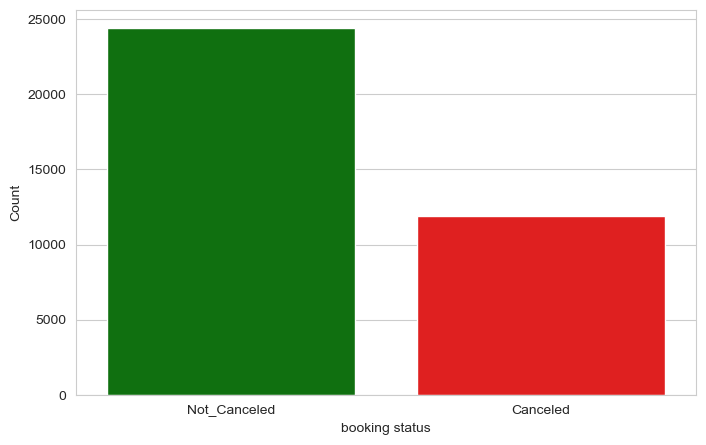


Class balance ratio: 2.05 : 1


In [10]:
status_count=df['booking status'].value_counts()
print (status_count)
sns.countplot(data=df,x='booking status',palette=["green","red"])
plt.xticks(['Not_Canceled','Canceled'])
plt.ylabel('Count')
plt.show()
print(f"\nClass balance ratio: {status_count['Not_Canceled']/status_count['Canceled']:.2f} : 1")


# Univariate Analysis  Feature Distributions
we use Univariate Analysis  Feature Distributions to know the skeness nad spread of data.

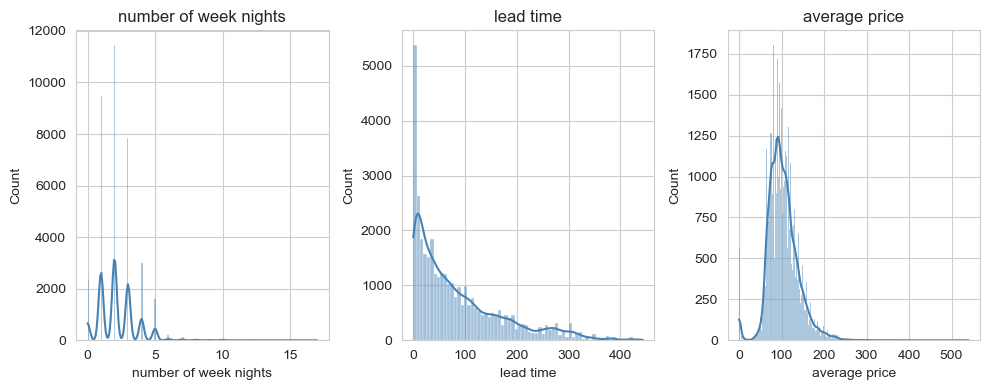

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(10,4))
sample_features = ["number of week nights", "lead time", "average price"]

for ax, feature in zip(axes.flatten(), sample_features):
    sns.histplot(df[feature], kde=True, ax=ax, color="steelblue")
    ax.set_title(feature)

plt.tight_layout()
plt.show()

# Bivariate Analysis  Features vs Target
Boxplots show how feature values differ between Canceld  and Not_Canceled tumors features with clear separation are likely strong predictors.


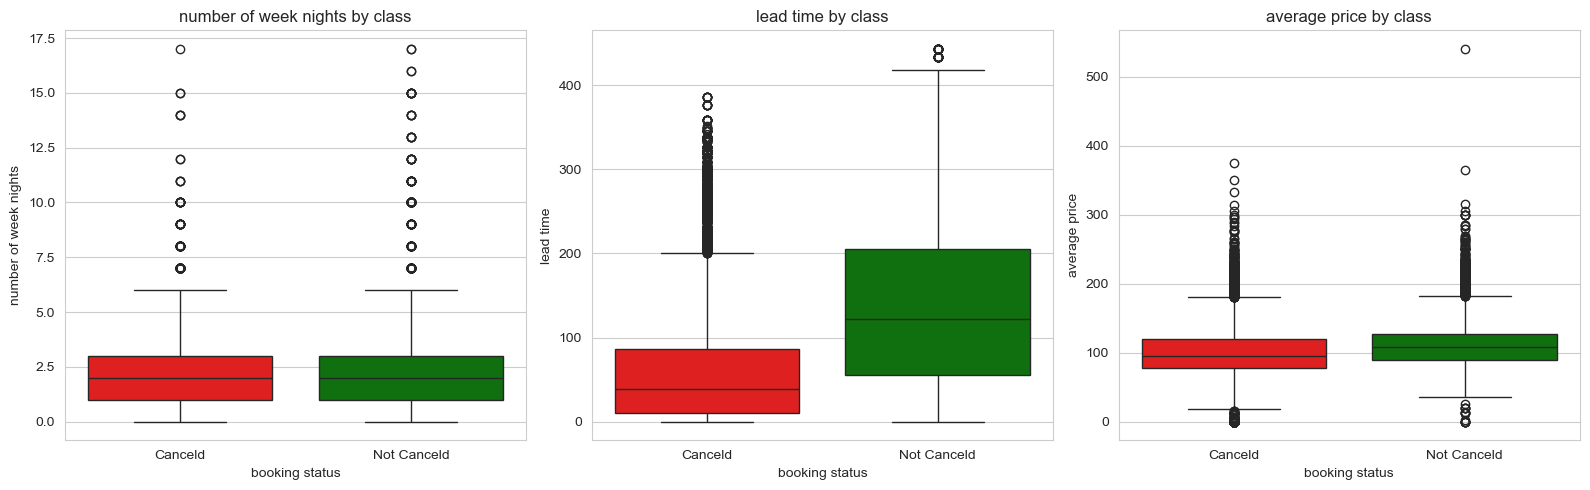

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax,featur in zip(axes,["number of week nights", "lead time", "average price"]):
    sns.boxplot(x='booking status',y=featur,data=df,ax=ax,palette=['red','green'])
    ax.set_xticklabels(['Canceld','Not Canceld'])
    ax.set_title(f'{featur} by class')
plt.tight_layout()
plt.show()

# Correlation Analysis

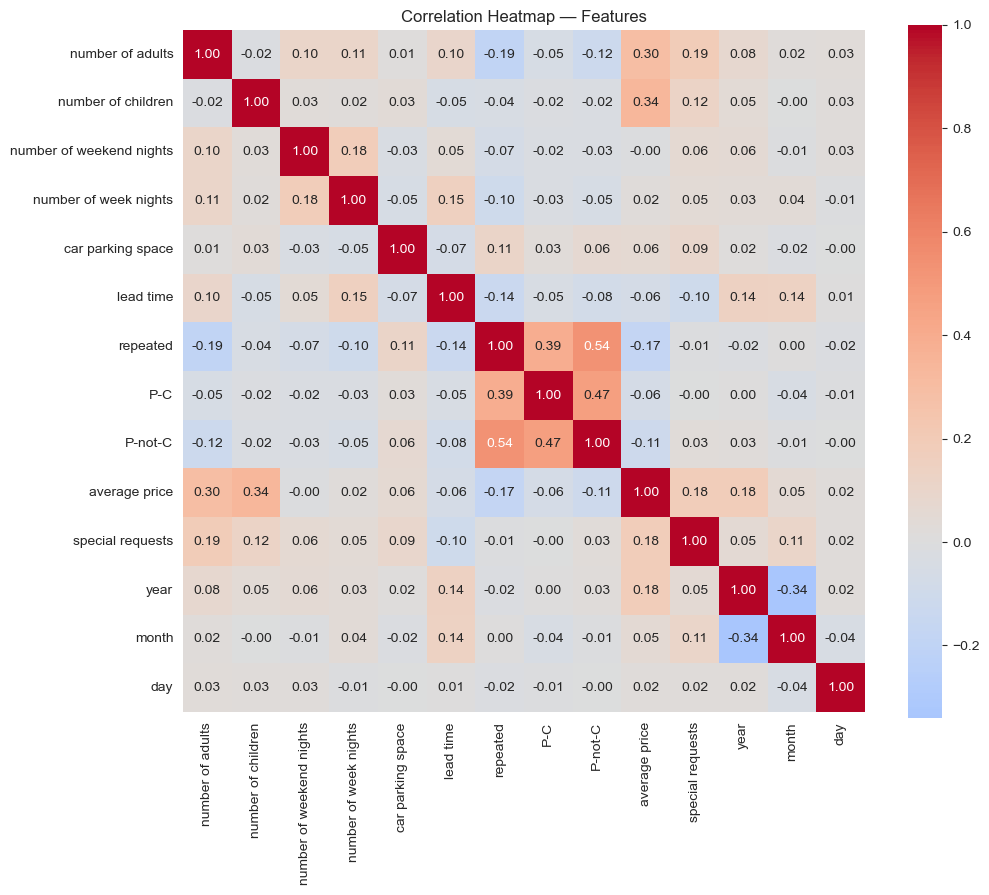

In [13]:
mean_features = [c for c in df.columns]
corr = df[mean_features].corr(numeric_only=True)

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap — Features")
plt.show()

# Outlier Detection (IQR Method)

In [14]:
def count_outliers_iqr(series):
    # Use pandas native type checker instead of numpy's
    if not pd.api.types.is_numeric_dtype(series):
        return 0
    
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    
    return ((series < lower) | (series > upper)).sum()

numeric_df = df.select_dtypes(include=[np.number])
outlier_summary = numeric_df.apply(count_outliers_iqr).sort_values(ascending=False)

print("Top 10 features by outlier count:")
outlier_summary.head(10)

Top 10 features by outlier count:


number of adults      10175
year                   6518
number of children     2702
average price          1696
lead time              1332
car parking space      1124
repeated                930
P-not-C                 812
special requests        762
P-C                     338
dtype: int64

 # Train-Test Split (Before Scaling/Encoding)

In [15]:
x=df.drop(columns=['booking status'])
y=df['booking status']

X_train, X_test, y_train, y_test = train_test_split(
    x,y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print ('Train Shape', X_train.shape)
print ('Test Shape', X_test.shape)
print ('\nTrain Class Balance\n',y_train.value_counts(normalize=True))
print ('\nTest Class Balance|n',y_test.value_counts(normalize=True))

Train Shape (29028, 17)
Test Shape (7257, 17)

Train Class Balance
 booking status
Not_Canceled    0.672351
Canceled        0.327649
Name: proportion, dtype: float64

Test Class Balance|n booking status
Not_Canceled    0.672316
Canceled        0.327684
Name: proportion, dtype: float64


In [16]:
df['type of meal']

0         Meal Plan 1
1        Not Selected
2         Meal Plan 1
3         Meal Plan 1
4        Not Selected
             ...     
36280     Meal Plan 2
36281     Meal Plan 1
36282     Meal Plan 1
36283     Meal Plan 1
36284     Meal Plan 1
Name: type of meal, Length: 36285, dtype: object

# ordinal Encoding

In [17]:
import pandas as pd
from sklearn.preprocessing import OrdinalEncoder

cols = ['type of meal', 'room type', 'market segment type']

# 1. Before Encoding values copy karein (Comparison ke liye)
before_df = X_train[cols].head().reset_index(drop=True)

# 2. Ordinal Encoding apply karein (PERMANENTLY update X_train and X_test)
oe = OrdinalEncoder()
X_train[cols] = oe.fit_transform(X_train[cols])
X_test[cols] = oe.transform(X_test[cols])

# 3. After Encoding values copy karein
after_df = X_train[cols].head().reset_index(drop=True)

# 4. Dono ko side-by-side Combine karein
comparison_df = pd.concat([before_df, after_df], axis=1)

# Columns ke names neat set karein
comparison_df.columns = [
    'type of meal (Before)', 'room type (Before)', 'market segment type (Before)',
    'type of meal (After)', 'room type (After)', 'market segment type (After)'
]

display(comparison_df)

,type of meal (Before),room type (Before),market segment type (Before),type of meal (After),room type (After),market segment type (After)
0,Meal Plan 1,Room_Type 1,Offline,0.0,0.0,3.0
1,Meal Plan 1,Room_Type 1,Offline,0.0,0.0,3.0
2,Meal Plan 1,Room_Type 4,Online,0.0,3.0,4.0
3,Meal Plan 1,Room_Type 1,Complementary,0.0,0.0,1.0
4,Meal Plan 1,Room_Type 4,Online,0.0,3.0,4.0


# Normalization
poray  data ko 0 say 1 ki rang may lana 

yeh data say skewness khuthum kar daytha hay 

In [18]:
from sklearn.preprocessing import MinMaxScaler

# 1. MinMaxScaler initialize karein
MinMax_scaler = MinMaxScaler()

# 2. Fit on X_train and Transform both
X_train_norm = MinMax_scaler.fit_transform(X_train)
X_test_norm = MinMax_scaler.transform(X_test)

# 3. Scaled arrays ko DataFrames mein convert karein
X_train_norm_df = pd.DataFrame(X_train_norm, columns=X_train.columns)
X_test_norm_df = pd.DataFrame(X_test_norm, columns=X_test.columns)
sample_cols = ['type of meal', 'room type', 'market segment type']
# 4. Results display karein
comparison_norm_df = pd.DataFrame({
    "Min (Before)": X_train[sample_cols].min().round(2),
    "Max (Before)": X_train[sample_cols].max().round(2),
    "Min (After)": X_train_norm_df[sample_cols].min().round(2),
    "Max (After)": X_train_norm_df[sample_cols].max().round(2),
})

display(comparison_norm_df)

,Min (Before),Max (Before),Min (After),Max (After)
type of meal,0.0,3.0,0.0,1.0
room type,0.0,6.0,0.0,1.0
market segment type,0.0,4.0,0.0,1.0


# Standardization
data kay mean ko 0 or stander division ko 1 kar day tha hay 

data say cutouses khathum kar day tha hay peek ko khuthum kar daytha hay 

In [19]:
# 1. StandardScaler initialize aur fit/transform karein
std_scaler = StandardScaler()
X_train_std = std_scaler.fit_transform(X_train)
X_test_std = std_scaler.transform(X_test)

# 2. DataFrame banayein
X_train_std_df = pd.DataFrame(X_train_std, columns=X_train.columns)
X_test_std_df = pd.DataFrame(X_test_std, columns=X_test.columns)

# 3. Mean aur Std Dev verify karein (Mean ≈ 0, Std Dev ≈ 1)
sample_cols = X_train.columns[:5]  # Automatically pehle 5 columns le lega

comparison_df = pd.DataFrame({
    "Mean (Before)": X_train[sample_cols].mean().round(2),
    "Std Dev (Before)": X_train[sample_cols].std().round(2),
    "Mean (After)": X_train_std_df[sample_cols].mean().round(2),
    "Std Dev (After)": X_train_std_df[sample_cols].std().round(2),
})

display(comparison_df)

,Mean (Before),Std Dev (Before),Mean (After),Std Dev (After)
number of adults,1.85,0.52,0.0,1.0
number of children,0.11,0.40,-0.0,1.0
number of weekend nights,0.81,0.87,-0.0,1.0
number of week nights,2.20,1.41,0.0,1.0
type of meal,0.52,1.05,0.0,1.0


# Impute data

In [20]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")
X_train_imputed = imputer.fit_transform(X_train_std_df)

X_train_std_imputed = pd.DataFrame(X_train_imputed, columns=X_train_std_df.columns)
print ("Data imputed succesfully")

Data imputed succesfully


# Cross validation
data ko mukhthlif hisso may banth kar wos ki tarianing karht hay.

model ko overfitting say buchatha hay 

In [21]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# 1. Aap ke exact 5 Models define karein
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=10000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "Support Vector Machine": SVC(
        kernel="linear",
        max_iter=1000,
        probability=True,
        class_weight="balanced",
        random_state=42,
    ),
}

# 2. Cross-Validation Loop (Using Imputed Data)
cv_results = []

for name, model in models.items():
    # 5 Folds Cross Validation
    scores = cross_val_score(
        model, X_train_std_imputed, y_train, cv=5, scoring="accuracy"
    )

    cv_results.append({
        "Model Name": name,
        "Mean Accuracy": np.mean(scores).round(4),
        "Std Deviation": np.std(scores).round(4),
    })

# 3. Decision Matrix Table (Sorted by Best Accuracy)
cv_comparison_df = (
    pd.DataFrame(cv_results)
    .sort_values(by="Mean Accuracy", ascending=False)
    .reset_index(drop=True)
)
display(cv_comparison_df)

,Model Name,Mean Accuracy,Std Deviation
0,Random Forest,0.8987,0.0028
1,Decision Tree,0.8627,0.0034
2,K-Nearest Neighbors,0.8450,0.0052
3,Logistic Regression,0.7759,0.0044
4,Support Vector Machine,0.6212,0.0579


##  Regularization

**Definition:** Regularization adds a penalty term to a model's loss function to discourage overly complex models (large coefficient magnitudes), reducing **overfitting** and improving generalization to unseen data.

**Types:**

| Type | Penalty term | Effect |
|---|---|---|
| **L1 (Lasso)** | $\lambda \sum |w_i|$ | Can shrink some coefficients to exactly **0** → performs automatic feature selection |
| **L2 (Ridge)** | $\lambda \sum w_i^2$ | Shrinks all coefficients smoothly toward 0, rarely exactly 0 |
| **ElasticNet** | Mix of L1 + L2 | Balances feature selection and coefficient shrinkage |

**Why it matters:**
- Without regularization, models (especially linear ones) can fit noise in the training data, achieving high training accuracy but poor test accuracy — the classic overfitting symptom.
- The regularization strength is controlled by a hyperparameter (`C` in scikit-learn's `LogisticRegression`, which is the **inverse** of regularization strength  smaller `C` means **stronger** regularization).

We compare L1 vs L2 regularization on our standardized training data.


In [22]:
results = []
for penalty, solver in [("l1", "liblinear"), ("l2", "liblinear")]:
    model = LogisticRegression(
        penalty=penalty,
        solver=solver,
        C=1.0,
        max_iter=10000,
        random_state=RANDOM_STATE,
    )
    # X_train_std ki jagah X_train_std_imputed use kiya hai
    scores = cross_val_score(
        model, X_train_std_imputed, y_train, cv=5, scoring="accuracy"
    )
    results.append({
        "Penalty": penalty.upper(),
        "Mean CV Accuracy": scores.mean().round(4),
        "Std": scores.std().round(4),
    })

reg_results_df = pd.DataFrame(results)
display(reg_results_df)

,Penalty,Mean CV Accuracy,Std
0,L1,0.8042,0.0052
1,L2,0.8042,0.0053


# Model Training
Models for classification 

In [23]:
import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# 1. Models Dictionary
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=10000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1
    ),
    
}

trained_models = {}

# 2. Training Loop with Imputed Data & Time Tracking
start_total = time.time()
for name, model in models.items():
    t0 = time.time()
    # X_train_std ki jagah X_train_std_imputed pass kiya hai
    model.fit(X_train_std_imputed, y_train)
    t1 = time.time()
    trained_models[name] = model
    print(f"✅ {name} trained successfully in {t1 - t0:.2f} seconds.")

print(
    f"\n🎉 All  models trained successfully! Total time:"
    f" {time.time() - start_total:.2f} seconds."
)

✅ Logistic Regression trained successfully in 0.21 seconds.
✅ Decision Tree trained successfully in 0.42 seconds.
✅ Random Forest trained successfully in 1.62 seconds.

🎉 All  models trained successfully! Total time: 2.25 seconds.


# MODEL TRAINING
Models for Regression

In [24]:
import time
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# 1. اوریجنل df میں سے صرف وہی Rows لیں جو y_train کی ہیں (29,028 rows)
y_train_price = df.loc[y_train.index, 'average price']

# 2. Regression Models
models_reg = {
    "Linear Regression": LinearRegression(),
    "Decision Tree Regressor": DecisionTreeRegressor(random_state=42),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
}

trained_reg_models = {}

# 3. Training Loop
start_total = time.time()
print("🚀 Training Regression Models for Room Price...\n" + "-" * 40)

for name, model in models_reg.items():
    t0 = time.time()
    
    # پروسیس شدہ فیچرز (X) اور فلٹر شدہ ٹارگٹ (y) دیں
    model.fit(X_train_std_imputed, y_train_price)
    
    t1 = time.time()
    trained_reg_models[name] = model
    print(f"✅ {name} trained successfully in {t1 - t0:.2f} seconds.")

print("-" * 40)
print(f"🎉 All Regression models trained successfully! Total time: {time.time() - start_total:.2f} seconds.")

🚀 Training Regression Models for Room Price...
----------------------------------------
✅ Linear Regression trained successfully in 0.09 seconds.
✅ Decision Tree Regressor trained successfully in 0.32 seconds.
✅ Random Forest Regressor trained successfully in 3.36 seconds.
----------------------------------------
🎉 All Regression models trained successfully! Total time: 3.77 seconds.


# Best Regression model 

In [25]:
# 1. Input Features (X) میں سے Target Column 'average price' کو Drop کریں
X_train_no_price = X_train_std_df.drop(columns=['average price'])
X_test_no_price = X_test_std_df.drop(columns=['average price'])

# Impute target-free features
X_train_reg_clean = imputer.fit_transform(X_train_no_price)
X_test_reg_clean = imputer.transform(X_test_no_price)

# Target Variable
y_train_price = df.loc[y_train.index, 'average price']
y_test_price = df.loc[y_test.index, 'average price']

# 2. Retrain Regression Models
models_reg = {
    "Linear Regression": LinearRegression(),
    "Decision Tree Regressor": DecisionTreeRegressor(random_state=42),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
}

trained_reg_models_clean = {}

for name, model in models_reg.items():
    model.fit(X_train_reg_clean, y_train_price)
    trained_reg_models_clean[name] = model

# 3. Correct Evaluation
results_clean = []

for name, model in trained_reg_models_clean.items():
    y_pred = model.predict(X_test_reg_clean)
    
    mae = mean_absolute_error(y_test_price, y_pred)
    mse = mean_squared_error(y_test_price, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test_price, y_pred)
    
    results_clean.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Output Comparison
results_clean_df = pd.DataFrame(results_clean).sort_values(by="R2 Score", ascending=False)
print("📊 Corrected Regression Models Comparison:")
display(results_clean_df)

print(f"\n🏆 Real Best Model: {results_clean_df.iloc[0]['Model']}")

NameError: name 'mean_absolute_error' is not defined

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot Style & Figure Size
plt.figure(figsize=(10, 5))

# R2 Score Barplot
ax = sns.barplot(x="R2 Score", y="Model", data=results_clean_df, palette="viridis")

plt.title("Corrected Regression Models Comparison (R2 Score)", fontsize=14, fontweight="bold")
plt.xlabel("R2 Score (Higher is Better)", fontsize=12)
plt.ylabel("Model", fontsize=12)
plt.xlim(0, 1.0)  # Standard range from 0 to 1

# Display R2 Score values on the bars
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f"{width:.4f}", 
                (width, p.get_y() + p.get_height() / 2.), 
                ha='left', va='center', xytext=(5, 0), textcoords='offset points')

plt.tight_layout()
plt.show()

##  Model Evaluation Metrics

No single metric tells the full story, especially with imbalanced classes (Section 2.5). We compute the standard suite of classification metrics for each model:

| Metric | Formula / Meaning | When it matters most |
|---|---|---|
| **Accuracy** | (TP+TN) / Total | Balanced classes only  misleading on imbalanced data |
| **Precision** | TP / (TP+FP) | When false positives are costly (e.g. flagging healthy patients as sick) |
| **Recall (Sensitivity)** | TP / (TP+FN) | When false negatives are costly (e.g. missing an actual cancer case) |
| **F1-Score** | Harmonic mean of Precision & Recall | Balances both, useful for imbalanced data |
| **ROC-AUC** | Area under the ROC curve | Measures ranking quality across all thresholds, threshold-independent |
| **Confusion Matrix** | TP, TN, FP, FN breakdown | Full picture of error types |

In medical diagnosis (our use case), **Recall is often prioritized**  missing a malignant tumor (false negative) is typically far more dangerous than a false alarm (false positive).


In [ ]:
from sklearn.metrics import make_scorer, f1_score
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# 1. Scorer setup
f1_scorer = make_scorer(f1_score, pos_label="Canceled")

# 2. Random Forest parameters
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "class_weight": ["balanced"],
}

# 3. Grid Search setup
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid=param_grid,
    cv=5,
    scoring=f1_scorer,
    n_jobs=-1,
)

# 4. Model Training
grid_search.fit(X_train_std_imputed, y_train)

print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best CV F1-Score: {grid_search.best_score_:.4f}")

# 5. Best Model Save
best_rf_model = grid_search.best_estimator_
trained_models["Random Forest (Tuned)"] = best_rf_model

In [ ]:
final_model = grid_search.best_estimator_
y_pred_final = final_model.predict(X_test_std)
y_proba_final = final_model.predict_proba(X_test_std)[:, 1]

print("=== Final Tuned Model Random Forest — Test Set Performance ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_final):.4f}")
print(
    f"Precision: {precision_score(y_test, y_pred_final, pos_label='Canceled'):.4f}"
)
print(
    f"Recall:    {recall_score(y_test, y_pred_final, pos_label='Canceled'):.4f}"
)
print(f"F1-Score:  {f1_score(y_test, y_pred_final, pos_label='Canceled'):.4f}")
print(
    f"ROC-AUC:   {roc_auc_score((y_test == 'Canceled').astype(int), y_proba_final):.4f}"
)

## The Key Teaching Concept: Building a Feature Schema

This is the core idea that powers the **dynamic Streamlit UI**. Instead of hardcoding widgets,
we describe each feature as a small JSON object:

```json
{
  "name": "bmi",
  "dtype": "numeric",
  "min": 0.5,
  "max": 15.0,
  "default": 3.8,
  "step": 0.1
}
```

For categorical features we'd instead store `"dtype": "categorical"` with an `"options"` list.
We build one schema per model and save it next to the model file. The Streamlit app will load
`model.pkl` + `schema.json` together and never needs to know the feature names in advance.


In [ ]:
import os
import json
import joblib
import pandas as pd

# 1. Folder creation (آپ کی بتائی ہوئی پاتھ)
ARTIFACT_DIR = "MODEL_FILES"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

# 2. Universal Schema Generator Function
def build_schema(df, step_decimals=2):
    """Auto-generate a schema for feature columns."""
    schema = []
    numeric_cols = df.select_dtypes(include=["number"]).columns.tolist()
    
    for feat in numeric_cols:
        col = df[feat]
        step = round((col.max() - col.min()) / 100, step_decimals) or 0.01
        schema.append({
            "name": feat,
            "dtype": "numeric",
            "min": float(col.min()),
            "max": float(col.max()),
            "default": float(col.mean()),
            "step": float(step),
        })
    return schema

# ==========================================
# A. SAVE CLASSIFICATION ARTIFACTS
# ==========================================
clf_model = grid_search.best_estimator_

clf_schema = {
    "task_type": "classification",
    "model_name": "Random Forest (Tuned)",
    "target_name": "booking status",
    "class_names": ["Not_Canceled", "Canceled"],
    "features": build_schema(X_train_std_df),
    "requires_scaling": True
}

# Save Classification Files
joblib.dump(clf_model, os.path.join(ARTIFACT_DIR, "classification_model.pkl"))
joblib.dump(imputer, os.path.join(ARTIFACT_DIR, "classification_imputer.pkl"))
if 'scaler' in locals():
    joblib.dump(scaler, os.path.join(ARTIFACT_DIR, "classification_scaler.pkl"))

with open(os.path.join(ARTIFACT_DIR, "classification_schema.json"), "w") as f:
    json.dump(clf_schema, f, indent=2)

print("✅ Classification Model, Scaler/Imputer, and Schema saved!")

# ==========================================
# B. SAVE REGRESSION ARTIFACTS
# ==========================================
# Best Regression Model selection (Random Forest)
reg_model = trained_reg_models_clean["Random Forest Regressor"]

reg_schema = {
    "task_type": "regression",
    "model_name": "Random Forest Regressor",
    "target_name": "average price",
    "features": build_schema(X_train_no_price),
    "requires_scaling": True
}

# Save Regression Files
joblib.dump(reg_model, os.path.join(ARTIFACT_DIR, "regression_model.pkl"))
joblib.dump(imputer, os.path.join(ARTIFACT_DIR, "regression_imputer.pkl"))
if 'scaler' in locals():
    joblib.dump(scaler, os.path.join(ARTIFACT_DIR, "regression_scaler.pkl"))

with open(os.path.join(ARTIFACT_DIR, "regression_schema.json"), "w") as f:
    json.dump(reg_schema, f, indent=2)

print("✅ Regression Model, Scaler/Imputer, and Schema saved!")

# ==========================================
# C. VERIFY CREATED FILES
# ==========================================
print("\n📂 Artifact folder contents (`MODEL_FILES`):")
print(os.listdir(ARTIFACT_DIR))

# Streamlit app 

In [ ]:
%%writefile streamlit_app.py
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import json
import os
import base64

st.set_page_config(page_title="Hotel Booking ML Portal", page_icon="🏨", layout="wide")

# ==========================================
# BACKGROUND VIDEO & CUSTOM GLASS CSS
# ==========================================
def get_base64_of_bin_file(bin_file):
    with open(bin_file, 'rb') as f:
        data = f.read()
    return base64.b64encode(data).decode()

# اگر آپ کی لوکل ویڈیو فائل کا نام "bg_video.mp4" ہے
try:
    video_base64 = get_base64_of_bin_file('bg_video.mp4')
    video_src = f"data:video/mp4;base64,{video_base64}"
except:
    video_src = "https://assets.mixkit.co/videos/preview/mixkit-abstract-technology-network-loop-27572-large.mp4"

custom_css = f"""
<style>
/* 1. بیک گراؤنڈ ویڈیو */
#bg-video {{
    position: fixed;
    right: 0;
    bottom: 0;
    min-width: 100%;
    min-height: 100%;
    z-index: -1;
    object-fit: cover;
    opacity: 0.35;
}}

.stApp {{
    background: transparent !important;
}}

/* 2. سلائیڈرز کے گرد کورل/گریے سافٹ بارڈر کا ہائی لائٹ */
div[data-testid="stSlider"] {{
    background: rgba(255, 255, 255, 0.05);
    border: 1px solid rgba(255, 127, 80, 0.3) !important; /* Coral Accent Border */
    border-radius: 12px;
    padding: 12px 16px;
    backdrop-filter: blur(5px);
    box-shadow: 0px 4px 10px rgba(0, 0, 0, 0.15);
    margin-bottom: 10px;
}}

/* 3. مین کارڈز اور ڈراپ ڈاؤن باکسز کا فریم */
div[data-baseweb="select"] {{
    border: 1px solid rgba(255, 127, 80, 0.4) !important;
    border-radius: 8px;
}}

/* 4. ہیڈنگز اور ٹیکسٹ کے گرد شیشے والا خوبصورت فریم */
.header-box {{
    background: rgba(20, 20, 25, 0.4);
    border: 1px solid rgba(255, 127, 80, 0.35);
    border-radius: 15px;
    padding: 18px 25px;
    backdrop-filter: blur(8px);
    margin-bottom: 20px;
}}
</style>

<video autoplay muted loop id="bg-video">
    <source src="{video_src}" type="video/mp4">
</video>
"""

st.markdown(custom_css, unsafe_allow_html=True)

# ==========================================
# MAIN TITLE
# ==========================================
st.markdown("""
<div class="header-box">
    <h1 style="margin:0; padding:0;">🏨 Hotel Booking ML Prediction Portal</h1>
    <p style="color: #cccccc; margin-top:5px;">This app builds inputs dynamically based on saved JSON schemas.</p>
</div>
""", unsafe_allow_html=True)

ARTIFACT_DIR = "MODEL_FILES"

EXCLUDE_COLS = ["year", "month", "day", "P-C", "P-not-C", "repeated", "average price"]
INT_COLS = [
    "number of adults", "number of children", "number of weekend nights",
    "number of week nights", "car parking space", "lead time", 
    "special requests", "room type", "market segment type", "type of meal"
]

@st.cache_resource
def load_artifacts(task_type):
    model_path = os.path.join(ARTIFACT_DIR, f"{task_type}_model.pkl")
    schema_path = os.path.join(ARTIFACT_DIR, f"{task_type}_schema.json")
    
    model = joblib.load(model_path)
    with open(schema_path, "r") as f:
        schema = json.load(f)
        
    return model, schema

# ==========================================
# DROPDOWN FOR MODEL SELECTION
# ==========================================
st.subheader("Choose a model to use:")
task_choice = st.selectbox(
    label="Select Task",
    options=["Classification", "Regression"],
    label_visibility="collapsed"
)

# ------------------------------------------
# TASK 1: CLASSIFICATION
# ------------------------------------------
if task_choice == "Classification":
    st.markdown("**Task: Classification | Model: Booking Status Predictor**")
    st.markdown("### Enter Guest Details")
    
    try:
        clf_model, clf_schema = load_artifacts("classification")
        clf_inputs = {}
        
        cols = st.columns(3)
        col_idx = 0
        
        for feature in clf_schema["features"]:
            name = feature["name"]
            label_name = name.replace("_", " ").title()
            
            if name in EXCLUDE_COLS:
                clf_inputs[name] = float(feature["default"])
                continue
                
            col = cols[col_idx % 3]
            col_idx += 1
            
            min_val = float(feature["min"])
            max_val = float(feature["max"])
            default_val = float(feature["default"])
            
            if min_val < 0:
                min_val = 0.0
            if max_val <= min_val:
                max_val = min_val + 5.0
            if default_val < min_val:
                default_val = min_val
            elif default_val > max_val:
                default_val = max_val

            if name in INT_COLS:
                clf_inputs[name] = col.slider(
                    label=label_name,
                    min_value=int(min_val),
                    max_value=int(max_val),
                    value=int(round(default_val)),
                    step=1,
                    key=f"clf_{name}"
                )
            else:
                clf_inputs[name] = col.slider(
                    label=label_name,
                    min_value=float(min_val),
                    max_value=float(max_val),
                    value=float(default_val),
                    step=0.1,
                    key=f"clf_{name}"
                )
        
        st.markdown("<br>", unsafe_allow_html=True)
        if st.button("Predict", type="primary"):
            input_df = pd.DataFrame([clf_inputs]).fillna(0)
            
            if hasattr(clf_model, "feature_names_in_"):
                input_df = input_df[[c for c in clf_model.feature_names_in_ if c in input_df.columns]]
            
            prediction = clf_model.predict(input_df)[0]
            
            st.divider()
            if str(prediction).lower() in ["canceled", "1"]:
                st.error("🚨 **High Risk of Cancellation!** (Booking is likely to be Canceled)")
            else:
                st.success("✅ **Booking Confirmed!** (Customer will likely check-in)")

    except Exception as e:
        st.error(f"Error loading classification artifacts: {e}")

# ------------------------------------------
# TASK 2: REGRESSION
# ------------------------------------------
else:
    st.markdown("**Task: Regression | Model: Room Price Predictor**")
    st.markdown("### Enter Guest Details")
    
    try:
        reg_model, reg_schema = load_artifacts("regression")
        reg_inputs = {}
        
        cols = st.columns(3)
        col_idx = 0
        
        for feature in reg_schema["features"]:
            name = feature["name"]
            label_name = name.replace("_", " ").title()
            
            if name in EXCLUDE_COLS:
                reg_inputs[name] = float(feature["default"])
                continue
                
            col = cols[col_idx % 3]
            col_idx += 1
            
            min_val = float(feature["min"])
            max_val = float(feature["max"])
            default_val = float(feature["default"])
            
            if min_val < 0:
                min_val = 0.0
            if max_val <= min_val:
                max_val = min_val + 5.0
            if default_val < min_val:
                default_val = min_val
            elif default_val > max_val:
                default_val = max_val

            if name in INT_COLS:
                reg_inputs[name] = col.slider(
                    label=label_name,
                    min_value=int(min_val),
                    max_value=int(max_val),
                    value=int(round(default_val)),
                    step=1,
                    key=f"reg_{name}"
                )
            else:
                reg_inputs[name] = col.slider(
                    label=label_name,
                    min_value=float(min_val),
                    max_value=float(max_val),
                    value=float(default_val),
                    step=0.1,
                    key=f"reg_{name}"
                )
        
        st.markdown("<br>", unsafe_allow_html=True)
        if st.button("Predict", type="primary"):
            input_df = pd.DataFrame([reg_inputs]).fillna(0)
            
            if hasattr(reg_model, "feature_names_in_"):
                input_df = input_df[[c for c in reg_model.feature_names_in_ if c in input_df.columns]]
                
            price_pred = reg_model.predict(input_df)[0]
            
            st.divider()
            st.metric(label="Predicted Average Price", value=f"${price_pred:.2f}")

    except Exception as e:
        st.error(f"Error loading regression artifacts: {e}")